### **Objectives**
- Load the three previously trained models; this notebook does **not** retrain them.
- Evaluate all models on the same deterministic held-out test manifest.
- Report accuracy, precision, sensitivity/recall, specificity, F1-score, ROC-AUC, PR-AUC, and confusion matrices.
- Compare ROC and precision–recall curves, prediction errors, inference time, and model file sizes.
- Generate Grad-CAM heatmaps and overlays for predictions, including selected false negatives and false positives.
- Save figures, per-image predictions, metrics, and a final comparison table to Google Drive.


In [1]:
# Import libraries and mount Google Drive for loading models and saving results.
import os
import glob
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve,
    ConfusionMatrixDisplay
)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Google Colab not detected. Ensure the paths below are valid in your environment.")

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN_Project"
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset", "Epic and CSCR hospital Dataset")
TEST_DIR = os.path.join(DATASET_DIR, "Test")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
GRADCAM_DIR = os.path.join(RESULTS_DIR, "gradcam_comparison")
os.makedirs(GRADCAM_DIR, exist_ok=True)

IMG_SIZE = (224, 224)
THRESHOLD = 0.50
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".jfif")

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Project directory exists:", os.path.isdir(PROJECT_DIR))
print("Test directory exists:", os.path.isdir(TEST_DIR))
print("Model directory exists:", os.path.isdir(MODEL_DIR))

Mounted at /content/drive
TensorFlow: 2.21.0
GPU devices: []
Project directory exists: True
Test directory exists: True
Model directory exists: True


In [2]:
# Locate the saved model files without guessing that a missing file exists.
MODEL_CANDIDATES = {
    "Custom CNN": [
        os.path.join(MODEL_DIR, "best_brain_tumor_cnn.keras"),
        os.path.join(MODEL_DIR, "brain_tumor_cnn_final.keras"),
    ],
    "EfficientNetB0": [
        os.path.join(MODEL_DIR, "efficientnetb0_final.keras"),
        os.path.join(MODEL_DIR, "best_efficientnetb0.keras"),
    ],
    "ConvNeXt-Tiny": [
        os.path.join(MODEL_DIR, "convnext_tiny_bce.keras"),
        os.path.join(MODEL_DIR, "convnext_tiny_focal.keras"),
        os.path.join(MODEL_DIR, "convnext_tiny_final.keras"),
    ],
}

def first_existing_path(paths):
    return next((p for p in paths if os.path.isfile(p)), None)

model_paths = {name: first_existing_path(paths) for name, paths in MODEL_CANDIDATES.items()}
for model_name, model_path in model_paths.items():
    print(f"{model_name}: {model_path if model_path else 'NOT FOUND'}")

print("\nModel directory contents:")
if os.path.isdir(MODEL_DIR):
    for item in sorted(os.listdir(MODEL_DIR)):
        print(" -", item)

missing = [name for name, path in model_paths.items() if path is None]
if missing:
    raise FileNotFoundError(
        "Could not locate saved model(s): " + ", ".join(missing) +
        ". Update MODEL_CANDIDATES above to match your Google Drive filenames."
    )

# To explicitly choose the focal-loss ConvNeXt model when both variants exist, set this to True.
USE_CONVNEXT_FOCAL = False
if USE_CONVNEXT_FOCAL:
    focal_path = os.path.join(MODEL_DIR, "convnext_tiny_focal.keras")
    if not os.path.isfile(focal_path):
        raise FileNotFoundError(f"Focal-loss ConvNeXt model not found: {focal_path}")
    model_paths["ConvNeXt-Tiny"] = focal_path

print("\nSelected model files:")
for name, path in model_paths.items():
    print(f"{name}: {path}")

Custom CNN: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_brain_tumor_cnn.keras
EfficientNetB0: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnetb0_final.keras
ConvNeXt-Tiny: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/convnext_tiny_bce.keras

Model directory contents:
 - best_brain_tumor_cnn.keras
 - best_convnext_bce.weights.h5
 - best_convnext_focal.weights.h5
 - best_efficientnetb0.keras
 - convnext_tiny_bce.keras
 - convnext_tiny_focal.keras
 - efficientnetb0_final.keras

Selected model files:
Custom CNN: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_brain_tumor_cnn.keras
EfficientNetB0: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnetb0_final.keras
ConvNeXt-Tiny: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/convnext_tiny_bce.keras


All three models must be evaluated on the **same image files and labels** for a fair comparison. This cell reads the four test class folders and sorts image paths deterministically. It also reports class counts so that dataset differences are visible before evaluation.

In [3]:
# Build one sorted test manifest shared by every model.
CLASS_MAPPING = {
    "notumor": 0,
    "glioma": 1,
    "meningioma": 1,
    "pituitary": 1,
}

records = []
for class_name, label in CLASS_MAPPING.items():
    class_dir = os.path.join(TEST_DIR, class_name)
    if not os.path.isdir(class_dir):
        raise FileNotFoundError(f"Required test class folder not found: {class_dir}")
    for file_path in sorted(glob.glob(os.path.join(class_dir, "*"))):
        if os.path.isfile(file_path) and file_path.lower().endswith(IMAGE_EXTENSIONS):
            records.append({
                "image_path": file_path,
                "original_class": class_name,
                "true_label": int(label),
                "true_class": "Tumourous" if label == 1 else "Non-Tumourous",
            })

test_df = pd.DataFrame(records).sort_values(
    ["original_class", "image_path"]
).reset_index(drop=True)

if test_df.empty:
    raise ValueError(f"No test images found under {TEST_DIR}")

assert test_df["image_path"].is_unique, "Duplicate image paths found in test manifest."
assert test_df["image_path"].map(os.path.isfile).all(), "Some image paths do not exist."

print("Total test images:", len(test_df))
print("\nCounts by original dataset folder:")
display(test_df["original_class"].value_counts().reindex(CLASS_MAPPING.keys(), fill_value=0).to_frame("count"))
print("\nBinary label counts (0=Non-Tumourous, 1=Tumourous):")
display(test_df["true_class"].value_counts().to_frame("count"))

manifest_path = os.path.join(GRADCAM_DIR, "shared_test_manifest.csv")
test_df.to_csv(manifest_path, index=False)
print("Shared test manifest saved to:", manifest_path)

Total test images: 2415

Counts by original dataset folder:


,count
original_class,
notumor,487
glioma,756
meningioma,546
pituitary,626



Binary label counts (0=Non-Tumourous, 1=Tumourous):


,count
true_class,
Tumourous,1928
Non-Tumourous,487


Shared test manifest saved to: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/gradcam_comparison/shared_test_manifest.csv


In [4]:
# Load each trained Keras model and print its input/output shapes.
loaded_models = {}
for model_name, model_path in model_paths.items():
    print(f"\nLoading {model_name} from: {model_path}")
    loaded_models[model_name] = tf.keras.models.load_model(model_path, compile=False)
    loaded_models[model_name].summary()
    print("Input shape:", loaded_models[model_name].input_shape)
    print("Output shape:", loaded_models[model_name].output_shape)


Loading Custom CNN from: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_brain_tumor_cnn.keras


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_image (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convnext_tiny (Functional)      │ (None, 768)            │    27,820,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 768)            │         1,536 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tumour_probability (Dense)      │ (None, 1)              │           769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,822,433 (106.13 MB)

 Trainable params: 16,650,241 (63.52 MB)

 Non-trainable params: 11,172,192 (42.62 MB)

Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


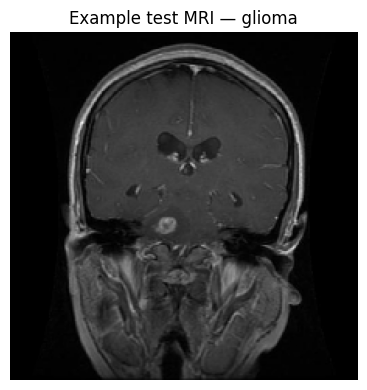

Tensor shape: (224, 224, 3) | dtype: float32 | min/max: 0.0 255.0


In [5]:
# Load an MRI image as a float32 RGB tensor with the expected 224-by-224 shape.
def load_mri_image(image_path):
    image = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE, color_mode="rgb")
    array = tf.keras.utils.img_to_array(image).astype(np.float32)
    return array

# Verify preprocessing visually on one test image.
sample_image = load_mri_image(test_df.loc[0, "image_path"])
plt.figure(figsize=(4, 4))
plt.imshow(np.clip(sample_image / 255.0, 0, 1))
plt.title(f"Example test MRI — {test_df.loc[0, 'original_class']}")
plt.axis("off")
plt.tight_layout()
plt.show()
print("Tensor shape:", sample_image.shape, "| dtype:", sample_image.dtype,
      "| min/max:", float(sample_image.min()), float(sample_image.max()))

The output layer is expected to be a single sigmoid probability for the Tumourous class. The default threshold is 0.50. Sensitivity/recall measures the proportion of tumourous images correctly identified; specificity measures the proportion of non-tumourous images correctly identified. These are dataset-level research metrics, not clinical validation.

In [7]:
# Keep this consistent with the threshold used in your existing notebook.
BATCH_SIZE = 32

y_true = test_df["true_label"].to_numpy(dtype=int)
all_predictions = {}
metric_rows = []

# Run inference in small batches to avoid loading the entire test set into RAM.
def predict_probabilities_batched(model, image_paths, batch_size=BATCH_SIZE):
    all_probs = []
    total = len(image_paths)

    for start in range(0, total, batch_size):
        batch_paths = image_paths[start:start + batch_size]

        # Reuse the notebook's existing image preprocessing function.
        batch_images = np.stack(
            [load_mri_image(path) for path in batch_paths],
            axis=0
        ).astype(np.float32, copy=False)

        outputs = model(batch_images, training=False)
        probs = np.asarray(outputs).reshape(-1)

        if len(probs) != len(batch_paths):
            raise ValueError(
                f"Expected {len(batch_paths)} outputs, received {len(probs)}."
            )
        if not np.all(np.isfinite(probs)):
            raise ValueError("Model returned non-finite predictions.")

        all_probs.extend(np.clip(probs, 0.0, 1.0).tolist())

        completed = min(start + batch_size, total)
        print(f"\rProcessed {completed}/{total} images", end="", flush=True)

    print()
    return np.asarray(all_probs, dtype=float)


# Evaluate each architecture using the same images, labels, and threshold.
for model_name, keras_model in loaded_models.items():
    print(f"\n===== Evaluating {model_name} =====")
    start_time = time.perf_counter()

    y_prob = predict_probabilities_batched(
        keras_model,
        test_df["image_path"].tolist()
    )
    elapsed = time.perf_counter() - start_time

    y_pred = (y_prob >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    metrics = {
        "model": model_name,
        "test_images": len(y_true),
        "threshold": THRESHOLD,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_tumour": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall_tumour_sensitivity": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1_tumour": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": (
            roc_auc_score(y_true, y_prob)
            if len(np.unique(y_true)) == 2 else np.nan
        ),
        "pr_auc_average_precision": (
            average_precision_score(y_true, y_prob)
            if len(np.unique(y_true)) == 2 else np.nan
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "total_inference_seconds": elapsed,
        "mean_inference_ms_per_image": (
            1000 * elapsed / len(y_true) if len(y_true) else np.nan
        ),
        "model_file_size_mb": (
            os.path.getsize(model_paths[model_name]) / (1024 ** 2)
        ),
    }

    all_predictions[model_name] = {
        "probabilities": y_prob,
        "predictions": y_pred,
        "metrics": metrics,
    }
    metric_rows.append(metrics)

    prediction_df = test_df.copy()
    prediction_df["tumour_probability"] = y_prob
    prediction_df["predicted_label"] = y_pred
    prediction_df["predicted_class"] = np.where(
        y_pred == 1, "Tumourous", "Non-Tumourous"
    )
    prediction_df["correct"] = (
        prediction_df["true_label"] == prediction_df["predicted_label"]
    )

    safe_name = (
        model_name.lower()
        .replace("-", "")
        .replace(" ", "_")
    )
    prediction_df.to_csv(
        os.path.join(
            GRADCAM_DIR,
            f"{safe_name}_test_predictions.csv"
        ),
        index=False
    )

    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Non-Tumourous", "Tumourous"],
        digits=4,
        zero_division=0
    ))
    print(f"Inference time: {elapsed:.2f} seconds")

# Save the cross-model comparison table.
metrics_df = pd.DataFrame(metric_rows)
metrics_path = os.path.join(
    GRADCAM_DIR, "model_comparison_metrics.csv"
)
metrics_df.to_csv(metrics_path, index=False)

display(metrics_df.style.format({
    "accuracy": "{:.4f}",
    "precision_tumour": "{:.4f}",
    "recall_tumour_sensitivity": "{:.4f}",
    "specificity": "{:.4f}",
    "f1_tumour": "{:.4f}",
    "roc_auc": "{:.4f}",
    "pr_auc_average_precision": "{:.4f}",
    "mean_inference_ms_per_image": "{:.2f}",
    "model_file_size_mb": "{:.2f}",
}))

print("Metrics saved to:", metrics_path)


===== Evaluating Custom CNN =====
Processed 2415/2415 images
               precision    recall  f1-score   support

Non-Tumourous     0.2017    1.0000    0.3356       487
    Tumourous     0.0000    0.0000    0.0000      1928

     accuracy                         0.2017      2415
    macro avg     0.1008    0.5000    0.1678      2415
 weighted avg     0.0407    0.2017    0.0677      2415

Inference time: 178.07 seconds

===== Evaluating EfficientNetB0 =====
Processed 2415/2415 images
               precision    recall  f1-score   support

Non-Tumourous     0.8730    0.9877    0.9268       487
    Tumourous     0.9968    0.9637    0.9800      1928

     accuracy                         0.9685      2415
    macro avg     0.9349    0.9757    0.9534      2415
 weighted avg     0.9718    0.9685    0.9692      2415

Inference time: 333.59 seconds

===== Evaluating ConvNeXt-Tiny =====
Processed 2415/2415 images
               precision    recall  f1-score   support

Non-Tumourous     0.957

,model,test_images,threshold,accuracy,precision_tumour,recall_tumour_sensitivity,specificity,f1_tumour,roc_auc,pr_auc_average_precision,tn,fp,fn,tp,total_inference_seconds,mean_inference_ms_per_image,model_file_size_mb
0,Custom CNN,2415,0.500000,0.2017,0.0000,0.0000,1.0000,0.0000,0.5000,0.7983,487,0,1928,0,178.065937,73.73,4.91
1,EfficientNetB0,2415,0.500000,0.9685,0.9968,0.9637,0.9877,0.9800,0.9947,0.9988,481,6,70,1858,333.589997,138.13,26.58
2,ConvNeXt-Tiny,2415,0.500000,0.9876,0.9953,0.9891,0.9815,0.9922,0.9983,0.9996,478,9,21,1907,4629.192495,1916.85,233.69


Metrics saved to: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/gradcam_comparison/model_comparison_metrics.csv


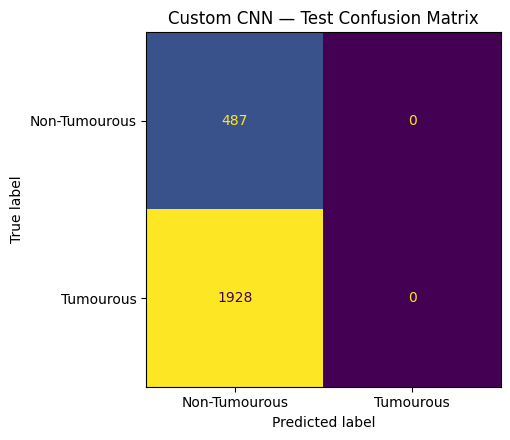

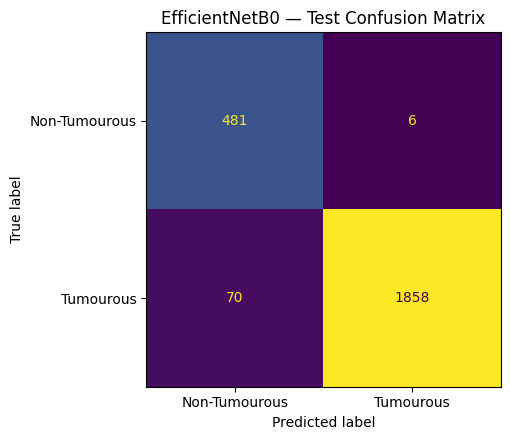

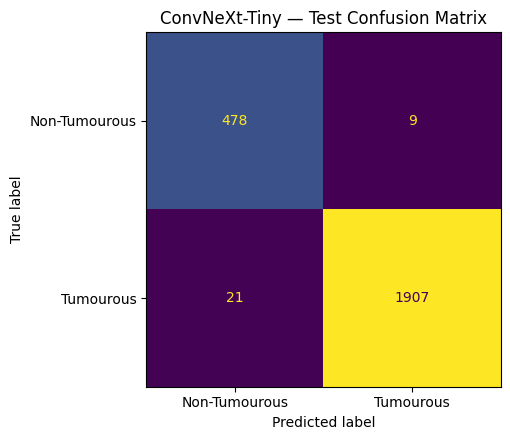

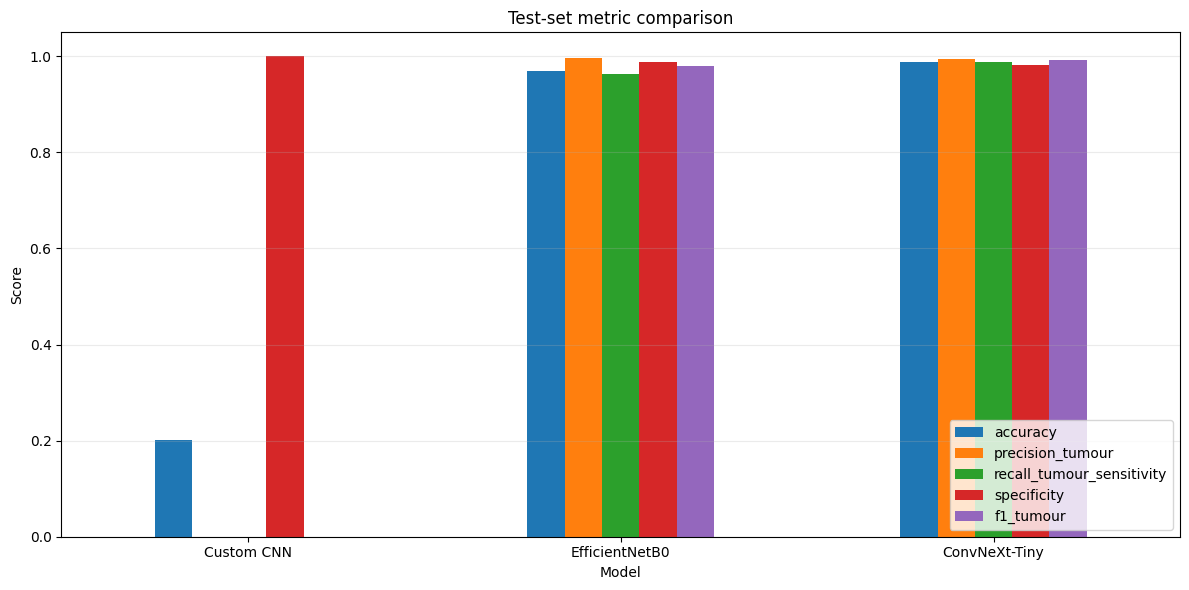

In [8]:
# Plot and save a confusion matrix for each model using the shared test labels.
for model_name, result in all_predictions.items():
    cm = confusion_matrix(y_true, result["predictions"], labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-Tumourous", "Tumourous"]
    ).plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"{model_name} — Test Confusion Matrix")
    plt.tight_layout()
    output_path = os.path.join(GRADCAM_DIR, f"{model_name.lower().replace('-', '').replace(' ', '_')}_confusion_matrix.png")
    plt.savefig(output_path, dpi=250, bbox_inches="tight")
    plt.show()

# Compare the principal threshold-dependent metrics across models.
metric_columns = [
    "accuracy", "precision_tumour", "recall_tumour_sensitivity",
    "specificity", "f1_tumour"
]
plot_df = metrics_df.set_index("model")[metric_columns]
ax = plot_df.plot(kind="bar", figsize=(12, 6), ylim=(0, 1.05))
ax.set_title("Test-set metric comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(GRADCAM_DIR, "model_metric_comparison.png"), dpi=250, bbox_inches="tight")
plt.show()

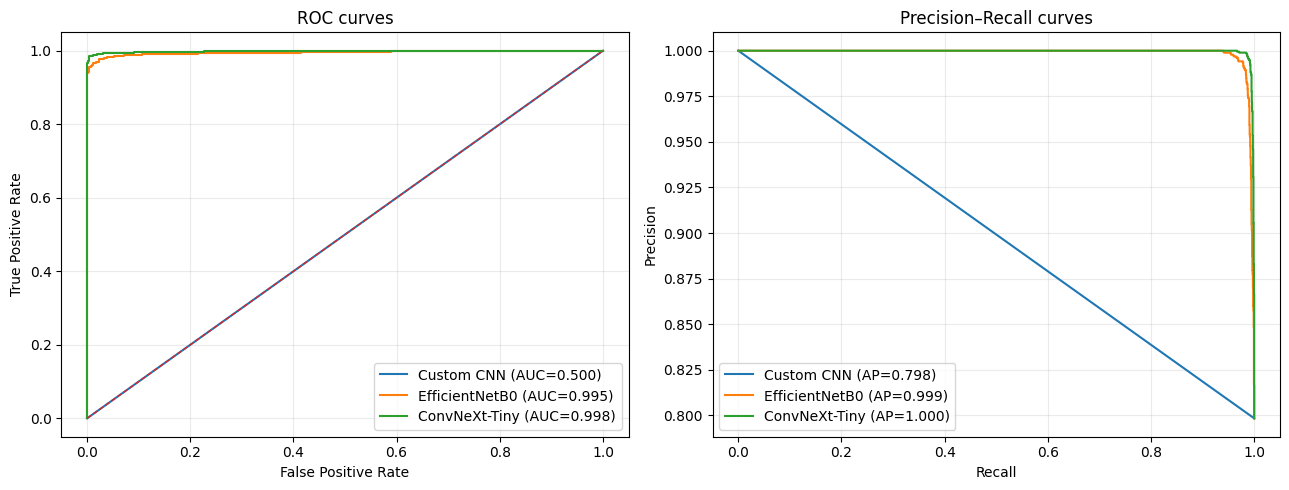

In [9]:
# Plot ROC and precision-recall curves using each model's continuous tumour probability.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name, result in all_predictions.items():
    fpr, tpr, _ = roc_curve(y_true, result["probabilities"])
    axes[0].plot(fpr, tpr, label=f"{model_name} (AUC={result['metrics']['roc_auc']:.3f})")

    precision_values, recall_values, _ = precision_recall_curve(y_true, result["probabilities"])
    axes[1].plot(recall_values, precision_values,
                 label=f"{model_name} (AP={result['metrics']['pr_auc_average_precision']:.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
axes[0].set_title("ROC curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].set_title("Precision–Recall curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(os.path.join(GRADCAM_DIR, "roc_and_precision_recall_curves.png"), dpi=250, bbox_inches="tight")
plt.show()

### Select the Grad-CAM target layers

Grad-CAM needs a spatial feature map (height × width × channels), not a pooled feature vector. The custom CNN is handled as a flat model. EfficientNetB0 and ConvNeXt-Tiny are handled using a spatial version of their pretrained backbone with the saved backbone weights copied across. Their classification heads are then reapplied exactly as defined in the supplied modelling notebooks.


In [10]:
# Build architecture-specific spatial feature extractors for Grad-CAM.
def find_last_conv2d_layer(model):
    candidates = []
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.Conv2D):
            candidates.append(layer)
        elif isinstance(layer, tf.keras.Model):
            nested = find_last_conv2d_layer(layer)
            if nested is not None:
                candidates.append(nested)
    return candidates[-1] if candidates else None

def find_nested_backbone(model, preferred_name):
    for layer in model.layers:
        if isinstance(layer, tf.keras.Model) and (
            preferred_name.lower() in layer.name.lower()
            or "efficientnet" in layer.name.lower()
            or "convnext" in layer.name.lower()
        ):
            return layer
    return None

In [14]:
# Create a Grad-CAM model by replaying the Custom CNN layers after the target layer.
custom_model = loaded_models["Custom CNN"]

# Build the model first so its layer weights and shapes are initialized.
_ = custom_model(tf.zeros((1, 224, 224, 3)), training=False)

custom_target = find_last_conv2d_layer(custom_model)

if custom_target is None:
    raise ValueError("No Conv2D layer found in the Custom CNN.")

# Create an explicit input tensor and replay the network layer by layer.
grad_input = tf.keras.Input(shape=(224, 224, 3))
x = grad_input
target_activation = None

for layer in custom_model.layers:
    x = layer(x)
    if layer is custom_target:
        target_activation = x

if target_activation is None:
    raise ValueError("Could not obtain the target convolutional activation.")

custom_grad_model = tf.keras.Model(
    inputs=grad_input,
    outputs=[target_activation, x],
    name="custom_cnn_gradcam_model"
)

print("Custom CNN target layer:", custom_target.name)
print("Target activation shape:", target_activation.shape)
print("Prediction output shape:", x.shape)

Custom CNN target layer: conv2d_3
Target activation shape: (None, 24, 24, 256)
Prediction output shape: (None, 1)


In [15]:
# EfficientNetB0: rebuild the backbone without global pooling, then transfer trained weights.
efficient_model = loaded_models["EfficientNetB0"]
efficient_backbone = find_nested_backbone(efficient_model, "efficientnet")
if efficient_backbone is None:
    raise ValueError("Could not locate the nested EfficientNetB0 backbone in the saved model.")

efficient_spatial = tf.keras.applications.EfficientNetB0(
    include_top=False, weights=None, input_shape=(224, 224, 3), pooling=None
)
efficient_spatial.set_weights(efficient_backbone.get_weights())
efficient_target = find_last_conv2d_layer(efficient_spatial)
if efficient_target is None:
    raise ValueError("No spatial Conv2D layer found in the EfficientNetB0 backbone.")
# Use the final spatial backbone output (after its final normalization/activation), before pooling.
efficient_feature_model = tf.keras.Model(
    efficient_spatial.input, [efficient_spatial.output, efficient_spatial.output],
    name="efficientnetb0_spatial_features"
)
print("EfficientNetB0 last convolution:", efficient_target.name,
      "| Grad-CAM feature map:", efficient_spatial.output.shape)

EfficientNetB0 last convolution: top_conv | Grad-CAM feature map: (None, 7, 7, 1280)


In [16]:
# ConvNeXt-Tiny: rebuild a spatial backbone and transfer trained backbone weights.
convnext_model = loaded_models["ConvNeXt-Tiny"]
convnext_backbone = find_nested_backbone(convnext_model, "convnext")
if convnext_backbone is None:
    raise ValueError("Could not locate the nested ConvNeXt-Tiny backbone in the saved model.")

convnext_spatial = tf.keras.applications.ConvNeXtTiny(
    include_top=False, weights=None, input_shape=(224, 224, 3), pooling=None
)
convnext_spatial.set_weights(convnext_backbone.get_weights())
convnext_target = find_last_conv2d_layer(convnext_spatial)
if convnext_target is None:
    raise ValueError("No spatial Conv2D layer found in the ConvNeXt-Tiny backbone.")
# Use the final spatial backbone output before global average pooling.
convnext_feature_model = tf.keras.Model(
    convnext_spatial.input, [convnext_spatial.output, convnext_spatial.output],
    name="convnext_tiny_spatial_features"
)
print("ConvNeXt-Tiny last convolution:", convnext_target.name,
      "| Grad-CAM feature map:", convnext_spatial.output.shape)

ConvNeXt-Tiny last convolution: convnext_tiny_stage_3_block_2_depthwise_conv | Grad-CAM feature map: (None, 7, 7, 768)


### Grad-CAM implementation

For binary classification, the target score is the model's tumour probability. Gradients are pooled across spatial positions to weight feature channels, then the resulting map is rectified and resized to the input image size. The overlay is intended for visual inspection only.

In [17]:
# Compute a normalized Grad-CAM heatmap with the model-specific computation path.
def normalize_heatmap(heatmap):
    heatmap = np.maximum(heatmap, 0)
    maximum = float(np.max(heatmap))
    if maximum > 0:
        heatmap = heatmap / maximum
    return heatmap.astype(np.float32)

In [18]:
def gradcam_custom(image_array):
    image_batch = tf.convert_to_tensor(np.expand_dims(image_array, axis=0), dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_outputs, predictions = custom_grad_model(image_batch, training=False)
        score = predictions[:, 0]
    gradients = tape.gradient(score, conv_outputs)
    if gradients is None:
        raise RuntimeError("Gradients are disconnected for the Custom CNN target layer.")
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)[0]
    heatmap = normalize_heatmap(heatmap.numpy())
    return tf.image.resize(heatmap[..., np.newaxis], IMG_SIZE).numpy().squeeze(), float(predictions[0, 0])

In [19]:
def gradcam_efficientnet(image_array):
    image_batch = tf.convert_to_tensor(np.expand_dims(image_array, axis=0), dtype=tf.float32)
    head_layers = [layer for layer in efficient_model.layers if layer is not efficient_backbone]
    # The supplied EfficientNet head is GAP -> Dropout -> Dense(sigmoid).
    with tf.GradientTape() as tape:
        conv_outputs, _ = efficient_feature_model(image_batch, training=False)
        tape.watch(conv_outputs)
        x = efficient_model.layers[-3](conv_outputs) if False else tf.reduce_mean(conv_outputs, axis=(1, 2))
        # Reuse the saved head weights through the actual top layers.
        x = efficient_model.layers[-2](x, training=False) if isinstance(efficient_model.layers[-2], tf.keras.layers.Dropout) else x
        prediction = efficient_model.layers[-1](x, training=False)
        score = prediction[:, 0]
    gradients = tape.gradient(score, conv_outputs)
    if gradients is None:
        raise RuntimeError("Gradients are disconnected for the EfficientNetB0 target layer.")
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = normalize_heatmap(tf.reduce_sum(weights * conv_outputs, axis=-1)[0].numpy())
    heatmap = tf.image.resize(heatmap[..., np.newaxis], IMG_SIZE).numpy().squeeze()
    return heatmap, float(prediction[0, 0])

In [20]:
def gradcam_convnext(image_array):
    image_batch = tf.convert_to_tensor(np.expand_dims(image_array, axis=0), dtype=tf.float32)
    # Reuse the trained classifier head after the spatial ConvNeXt backbone.
    head_layers = convnext_model.layers
    layer_names = [layer.name for layer in head_layers]
    norm_layer = next((layer for layer in head_layers if isinstance(layer, tf.keras.layers.LayerNormalization)), None)
    dropout_layer = next((layer for layer in head_layers if isinstance(layer, tf.keras.layers.Dropout)), None)
    dense_layer = next((layer for layer in reversed(head_layers) if isinstance(layer, tf.keras.layers.Dense)), None)
    if norm_layer is None or dense_layer is None:
        raise ValueError("Expected LayerNormalization and Dense classification layers in ConvNeXt model.")
    with tf.GradientTape() as tape:
        conv_outputs, _ = convnext_feature_model(image_batch, training=False)
        tape.watch(conv_outputs)
        x = tf.reduce_mean(conv_outputs, axis=(1, 2))
        x = norm_layer(x, training=False)
        if dropout_layer is not None:
            x = dropout_layer(x, training=False)
        prediction = dense_layer(x)
        score = prediction[:, 0]
    gradients = tape.gradient(score, conv_outputs)
    if gradients is None:
        raise RuntimeError("Gradients are disconnected for the ConvNeXt-Tiny target layer.")
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = normalize_heatmap(tf.reduce_sum(weights * conv_outputs, axis=-1)[0].numpy())
    heatmap = tf.image.resize(heatmap[..., np.newaxis], IMG_SIZE).numpy().squeeze()
    return heatmap, float(prediction[0, 0])

In [21]:
GRADCAM_FUNCTIONS = {
    "Custom CNN": gradcam_custom,
    "EfficientNetB0": gradcam_efficientnet,
    "ConvNeXt-Tiny": gradcam_convnext,
}

print("Grad-CAM functions registered:", list(GRADCAM_FUNCTIONS))

Grad-CAM functions registered: ['Custom CNN', 'EfficientNetB0', 'ConvNeXt-Tiny']


Custom CNN: Grad-CAM p=0.000000; evaluation p=0.000000; absolute difference=0
EfficientNetB0: Grad-CAM p=0.903288; evaluation p=0.993078; absolute difference=0.0897896
ConvNeXt-Tiny: Grad-CAM p=0.999978; evaluation p=0.999993; absolute difference=1.55568e-05


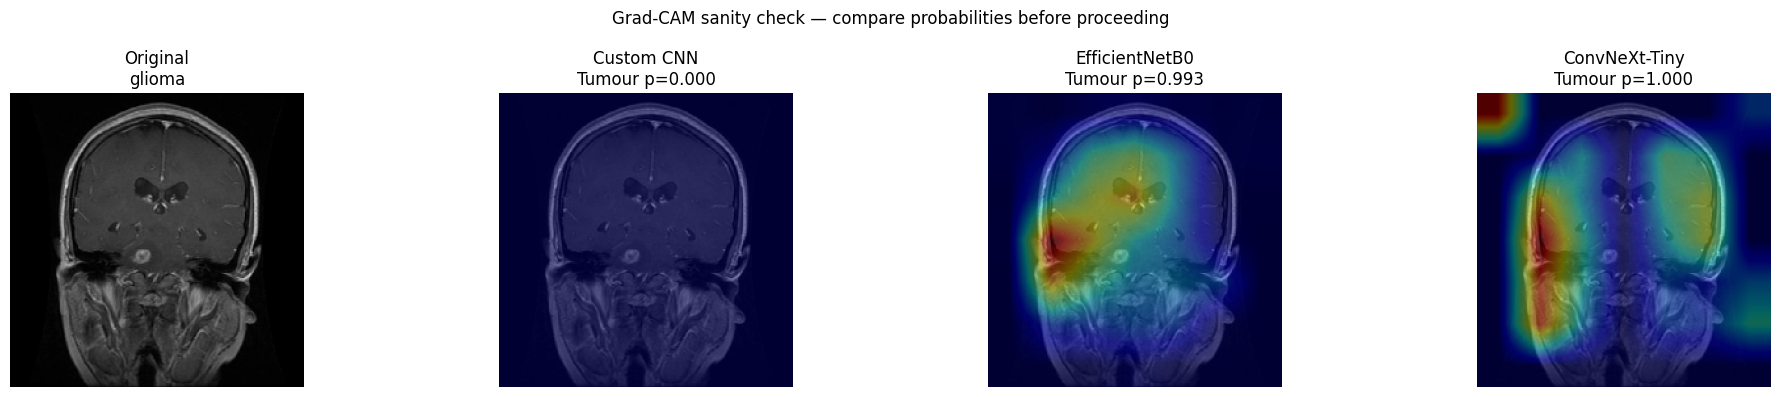

In [22]:
# Validate one Grad-CAM map per model and compare its probability with normal inference.
validation_index = 0
validation_path = test_df.loc[validation_index, "image_path"]
validation_image = load_mri_image(validation_path)

fig, axes = plt.subplots(1, 1 + len(loaded_models), figsize=(5 * (1 + len(loaded_models)), 4))
axes[0].imshow(np.clip(validation_image / 255.0, 0, 1))
axes[0].set_title(f"Original\n{test_df.loc[validation_index, 'original_class']}")
axes[0].axis("off")

for ax, (model_name, gradcam_fn) in zip(axes[1:], GRADCAM_FUNCTIONS.items()):
    heatmap, gradcam_probability = gradcam_fn(validation_image)
    normal_probability = all_predictions[model_name]["probabilities"][validation_index]
    print(f"{model_name}: Grad-CAM p={gradcam_probability:.6f}; evaluation p={normal_probability:.6f}; "
          f"absolute difference={abs(gradcam_probability-normal_probability):.6g}")
    ax.imshow(np.clip(validation_image / 255.0, 0, 1))
    ax.imshow(heatmap, cmap="jet", alpha=0.40)
    ax.set_title(f"{model_name}\nTumour p={normal_probability:.3f}")
    ax.axis("off")

plt.suptitle("Grad-CAM sanity check — compare probabilities before proceeding")
plt.tight_layout()
plt.show()

In [23]:
# Select representative cases shared across all models.
selected_indices = []
def add_first_index(mask, description):
    matches = np.flatnonzero(np.asarray(mask))
    if len(matches):
        idx = int(matches[0])
        if idx not in selected_indices:
            selected_indices.append(idx)
            print(f"Selected {description}: test index {idx} | {test_df.loc[idx, 'image_path']}")

add_first_index(y_true == 1, "tumourous example")
add_first_index(y_true == 0, "non-tumourous example")

for model_name, result in all_predictions.items():
    add_first_index((y_true == 1) & (result["predictions"] == 0), f"{model_name} false negative")
    add_first_index((y_true == 0) & (result["predictions"] == 1), f"{model_name} false positive")

# Limit representative visualizations while preserving all metrics/predictions for the complete test set.
MAX_CASES_TO_RENDER = 8
selected_indices = selected_indices[:MAX_CASES_TO_RENDER]
print("\nNumber of representative cases:", len(selected_indices))

Selected tumourous example: test index 0 | /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Test/glioma/1049.jpg
Selected non-tumourous example: test index 1302 | /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Test/notumor/1107.jpg
Selected EfficientNetB0 false negative: test index 457 | /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Test/glioma/G_68.jpg
Selected EfficientNetB0 false positive: test index 1346 | /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Test/notumor/1153.jpg
Selected ConvNeXt-Tiny false negative: test index 469 | /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Test/glioma/G_682_RO_.jpg
Selected ConvNeXt-Tiny false positive: test index 1425 | /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Test/notumor/1232.jpg

Number of representative cas

In [24]:
# Render the same MRI with each model's Grad-CAM overlay and save each comparison figure.
def safe_stem(path):
    return Path(path).stem[:80].replace(" ", "_")

for idx in selected_indices:
    row = test_df.iloc[idx]
    image_array = load_mri_image(row["image_path"])
    fig, axes = plt.subplots(1, 1 + len(GRADCAM_FUNCTIONS), figsize=(5 * (1 + len(GRADCAM_FUNCTIONS)), 4.5))

    axes[0].imshow(np.clip(image_array / 255.0, 0, 1))
    axes[0].set_title(f"Original MRI\nTrue: {row['true_class']}")
    axes[0].axis("off")

    for ax, (model_name, gradcam_fn) in zip(axes[1:], GRADCAM_FUNCTIONS.items()):
        heatmap, p_gradcam = gradcam_fn(image_array)
        result = all_predictions[model_name]
        p_eval = result["probabilities"][idx]
        predicted_label = int(result["predictions"][idx])
        predicted_text = "Tumourous" if predicted_label else "Non-Tumourous"
        correctness = "Correct" if predicted_label == int(row["true_label"]) else "ERROR"
        ax.imshow(np.clip(image_array / 255.0, 0, 1))
        ax.imshow(heatmap, cmap="jet", alpha=0.40, vmin=0, vmax=1)
        ax.set_title(f"{model_name}\n{predicted_text} ({correctness})\nTumour p={p_eval:.3f}")
        ax.axis("off")

    plt.suptitle(f"Grad-CAM comparison — test index {idx}")
    plt.tight_layout()
    out_path = os.path.join(GRADCAM_DIR, f"gradcam_case_{idx:04d}_{safe_stem(row['image_path'])}.png")
    plt.savefig(out_path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", out_path)

Output hidden; open in https://colab.research.google.com to view.

In [25]:
# Optionally export every image's Grad-CAM overlay and an index CSV for each model.
EXPORT_ALL_GRADCAM = False

if EXPORT_ALL_GRADCAM:
    all_overlay_rows = []
    for model_name, gradcam_fn in GRADCAM_FUNCTIONS.items():
        model_folder = os.path.join(GRADCAM_DIR, "all_overlays", model_name.lower().replace("-", "").replace(" ", "_"))
        os.makedirs(model_folder, exist_ok=True)
        for idx, row in test_df.iterrows():
            image_array = load_mri_image(row["image_path"])
            heatmap, _ = gradcam_fn(image_array)
            probability = all_predictions[model_name]["probabilities"][idx]
            predicted_label = int(all_predictions[model_name]["predictions"][idx])

            fig, ax = plt.subplots(figsize=(4, 4))
            ax.imshow(np.clip(image_array / 255.0, 0, 1))
            ax.imshow(heatmap, cmap="jet", alpha=0.40, vmin=0, vmax=1)
            ax.axis("off")
            ax.set_title(f"{model_name} | tumour p={probability:.3f}")
            overlay_path = os.path.join(model_folder, f"overlay_{idx:05d}.png")
            plt.savefig(overlay_path, dpi=150, bbox_inches="tight", pad_inches=0)
            plt.close(fig)

            all_overlay_rows.append({
                "model": model_name,
                "test_index": int(idx),
                "image_path": row["image_path"],
                "true_label": int(row["true_label"]),
                "predicted_label": predicted_label,
                "tumour_probability": float(probability),
                "correct": bool(predicted_label == int(row["true_label"])),
                "overlay_path": overlay_path,
            })

    overlay_index_path = os.path.join(GRADCAM_DIR, "all_gradcam_overlay_index.csv")
    pd.DataFrame(all_overlay_rows).to_csv(overlay_index_path, index=False)
    print("All Grad-CAM overlays and index saved under:", os.path.join(GRADCAM_DIR, "all_overlays"))
    print("Overlay index:", overlay_index_path)
else:
    print("Full overlay export skipped. Set EXPORT_ALL_GRADCAM = True to enable it.")

Full overlay export skipped. Set EXPORT_ALL_GRADCAM = True to enable it.


In [26]:
# Save a compact error-analysis table for each model.
error_frames = []
for model_name, result in all_predictions.items():
    pred_df = test_df.copy()
    pred_df["model"] = model_name
    pred_df["tumour_probability"] = result["probabilities"]
    pred_df["predicted_label"] = result["predictions"]
    pred_df["predicted_class"] = np.where(pred_df["predicted_label"] == 1, "Tumourous", "Non-Tumourous")
    pred_df["error_type"] = np.select(
        [
            (pred_df["true_label"] == 1) & (pred_df["predicted_label"] == 0),
            (pred_df["true_label"] == 0) & (pred_df["predicted_label"] == 1),
        ],
        ["False Negative", "False Positive"],
        default="Correct"
    )
    error_frames.append(pred_df[pred_df["error_type"] != "Correct"])

errors_df = pd.concat(error_frames, ignore_index=True) if error_frames else pd.DataFrame()
errors_path = os.path.join(GRADCAM_DIR, "false_positive_false_negative_analysis.csv")
errors_df.to_csv(errors_path, index=False)
print("Error analysis saved to:", errors_path)
display(errors_df.groupby(["model", "error_type"]).size().unstack(fill_value=0))

Error analysis saved to: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/gradcam_comparison/false_positive_false_negative_analysis.csv


error_type,False Negative,False Positive
model,,
ConvNeXt-Tiny,21,9
Custom CNN,1928,0
EfficientNetB0,70,6


### Select a candidate model for the final application

The cell below offers a **transparent, metric-based candidate** by ranking models on tumour sensitivity first, then tumour F1, ROC-AUC, and specificity. This is a research decision rule—not a clinical threshold—and should be reviewed against the actual confusion matrices and error cases. The notebook does not automatically claim a model is clinically safe.

In [27]:
# Rank candidate models using the documented priority order and save the final comparison summary.
ranked_metrics = metrics_df.sort_values(
    by=["recall_tumour_sensitivity", "f1_tumour", "roc_auc", "specificity"],
    ascending=[False, False, False, False],
    na_position="last"
).reset_index(drop=True)

candidate_model = ranked_metrics.loc[0, "model"] if not ranked_metrics.empty else None
print("Candidate based on sensitivity-first research ranking:", candidate_model)
display(ranked_metrics[[
    "model", "accuracy", "precision_tumour", "recall_tumour_sensitivity",
    "specificity", "f1_tumour", "roc_auc", "pr_auc_average_precision",
    "fn", "fp", "mean_inference_ms_per_image", "model_file_size_mb"
]])

final_summary = {
    "project": "Image Analysis of Brain Tumor",
    "task": "Binary MRI classification",
    "test_images": int(len(test_df)),
    "threshold": THRESHOLD,
    "models_compared": list(loaded_models.keys()),
    "candidate_model_sensitivity_first": candidate_model,
    "model_paths": model_paths,
    "metrics": metrics_df.replace({np.nan: None}).to_dict(orient="records"),
    "note": "Educational research prototype only; not for clinical diagnosis."
}
summary_path = os.path.join(GRADCAM_DIR, "final_model_comparison_summary.json")
with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(final_summary, file, indent=2)
ranked_metrics.to_csv(os.path.join(GRADCAM_DIR, "ranked_model_comparison.csv"), index=False)
print("Saved final summary:", summary_path)

Candidate based on sensitivity-first research ranking: ConvNeXt-Tiny


,model,accuracy,precision_tumour,recall_tumour_sensitivity,specificity,f1_tumour,roc_auc,pr_auc_average_precision,fn,fp,mean_inference_ms_per_image,model_file_size_mb
0,ConvNeXt-Tiny,0.987578,0.995303,0.989108,0.98152,0.992196,0.998282,0.999596,21,9,1916.849894,233.691910
1,EfficientNetB0,0.968530,0.996781,0.963693,0.98768,0.979958,0.994695,0.998775,70,6,138.132504,26.579081
2,Custom CNN,0.201656,0.000000,0.000000,1.00000,0.000000,0.500000,0.798344,1928,0,73.733307,4.913216


Saved final summary: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/gradcam_comparison/final_model_comparison_summary.json


In [28]:
# List all artifacts generated by this notebook for final report preparation.
for root, directories, files in os.walk(GRADCAM_DIR):
    for filename in sorted(files):
        file_path = os.path.join(root, filename)
        print(f"{os.path.relpath(file_path, GRADCAM_DIR)}  ({os.path.getsize(file_path) / 1024:.1f} KB)")

convnexttiny_confusion_matrix.png  (54.7 KB)
convnexttiny_test_predictions.csv  (397.8 KB)
custom_cnn_confusion_matrix.png  (53.5 KB)
custom_cnn_test_predictions.csv  (372.7 KB)
efficientnetb0_confusion_matrix.png  (54.4 KB)
efficientnetb0_test_predictions.csv  (399.8 KB)
false_positive_false_negative_analysis.csv  (356.2 KB)
final_model_comparison_summary.json  (2.4 KB)
gradcam_case_0000_1049.png  (395.4 KB)
gradcam_case_0457_G_68.png  (386.0 KB)
gradcam_case_0469_G_682_RO_.png  (340.7 KB)
gradcam_case_1302_1107.png  (377.2 KB)
gradcam_case_1346_1153.png  (432.7 KB)
gradcam_case_1425_1232.png  (489.9 KB)
model_comparison_metrics.csv  (0.8 KB)
model_metric_comparison.png  (92.7 KB)
ranked_model_comparison.csv  (0.8 KB)
roc_and_precision_recall_curves.png  (219.1 KB)
shared_test_manifest.csv  (311.8 KB)
